In [ ]:
'''
we're gonna make some training data for off center stuff!!...after a new range
'''

In [2]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt

# importlib.reload(plot_time_series)
import gc  # garbage collector
# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os

import importlib

In [ ]:
#okay so i found what we had last time in dimming_training_data.py

In [ ]:
#wait damn i forgor first i will do it with the new range of training stamps
#let's check them out

In [26]:
stamp = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_neg_better/images/ztf_20220820237546_000798_zr_c01_x_0001._4_stamps.npy")

In [4]:
stamp


array([[[0.00624334, 0.00660245, 0.00632046, ..., 0.0079392 ,
         0.00688292, 0.00823027],
        [0.006488  , 0.00636676, 0.00745481, ..., 0.00822095,
         0.00768941, 0.00870718],
        [0.00648035, 0.00647218, 0.00656595, ..., 0.00816755,
         0.0075678 , 0.00840155],
        ...,
        [0.00660958, 0.00690714, 0.00702078, ..., 0.00798727,
         0.00736901, 0.00732198],
        [0.00660102, 0.00634685, 0.00687382, ..., 0.00876828,
         0.0069878 , 0.00755028],
        [0.00700747, 0.00649557, 0.00643243, ..., 0.00952366,
         0.00846139, 0.00857242]],

       [[0.00687852, 0.00661806, 0.00702007, ..., 0.0071496 ,
         0.00502441, 0.0062626 ],
        [0.00758135, 0.0063833 , 0.00710344, ..., 0.00678567,
         0.00632531, 0.0073461 ],
        [0.00558432, 0.00670127, 0.00646029, ..., 0.00559726,
         0.00593045, 0.00599174],
        ...,
        [0.00640243, 0.00625   , 0.00663978, ..., 0.00636401,
         0.00511105, 0.0065034 ],
        [0.0

In [29]:
info = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_neg_better/info/ztf_20220820237546_000798_zr_c01_x_0001._4_stamps_info.npy")

In [30]:
info

array([[8.000e-01, 5.000e+00, 7.400e+01, 3.020e+02],
       [8.000e-01, 5.000e+00, 1.570e+02, 4.390e+02],
       [7.000e-01, 8.000e+00, 3.730e+02, 3.026e+03],
       [9.500e-01, 5.000e+00, 6.650e+02, 2.597e+03],
       [9.000e-01, 8.000e+00, 1.224e+03, 2.183e+03],
       [5.000e-01, 6.000e+00, 1.371e+03, 2.906e+03],
       [9.950e-01, 7.000e+00, 1.673e+03, 2.580e+03],
       [6.000e-01, 6.000e+00, 1.926e+03, 1.734e+03],
       [5.000e-01, 6.000e+00, 2.015e+03, 1.085e+03],
       [8.000e-01, 9.000e+00, 2.769e+03, 2.505e+03]])

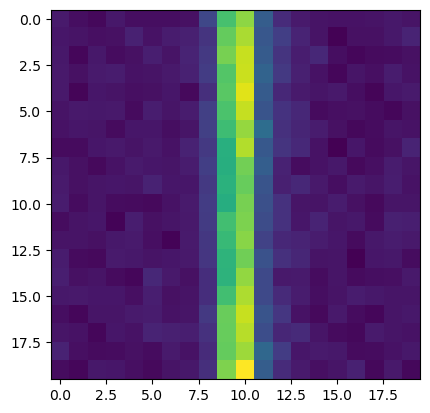

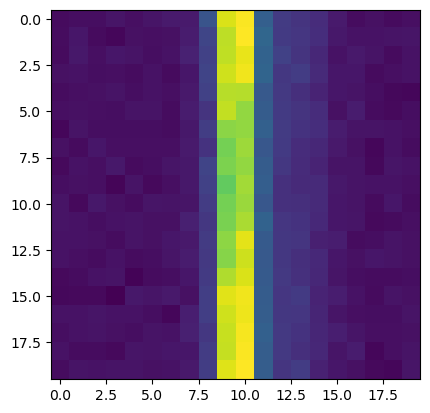

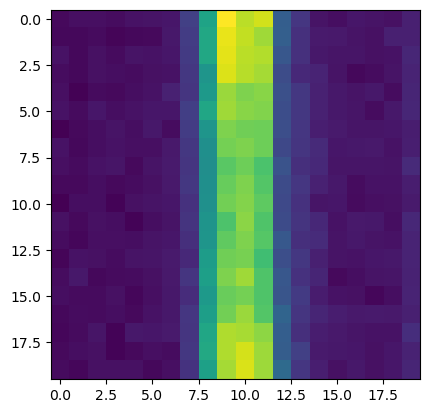

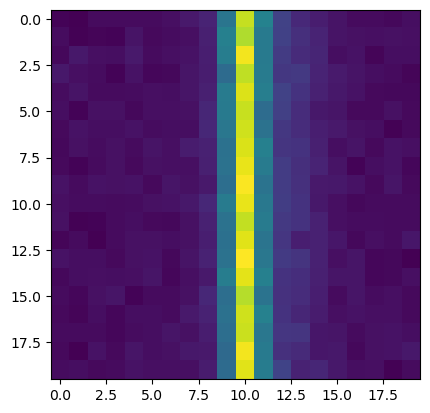

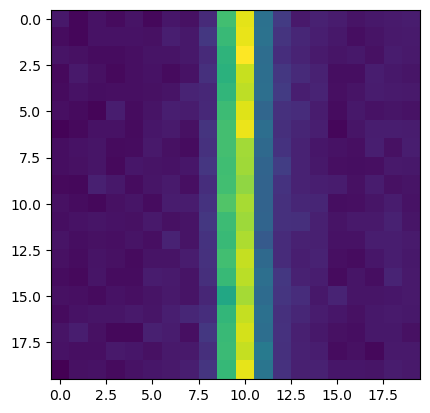

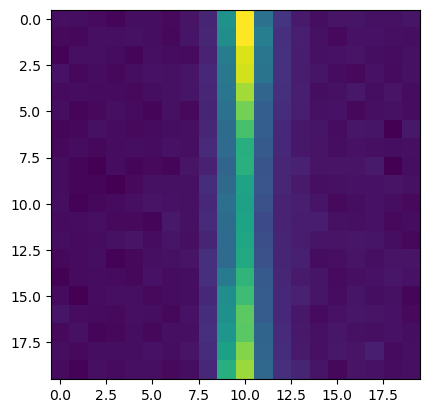

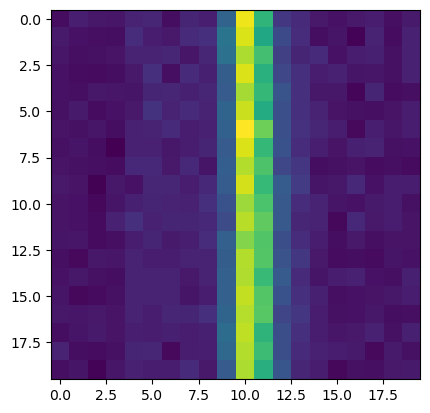

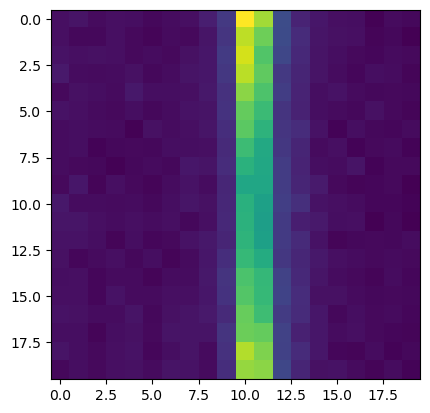

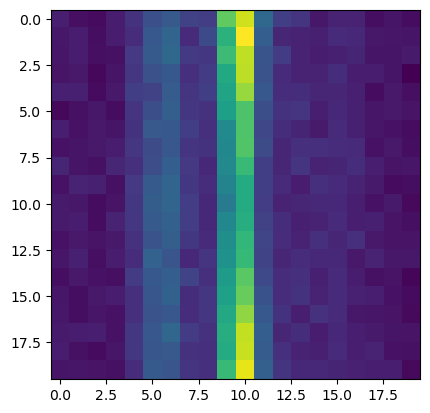

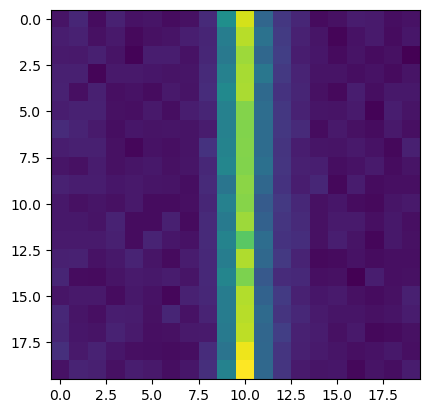

In [27]:
for i in range(len(stamp)):
    plt.imshow(stamp[i])
    plt.show()

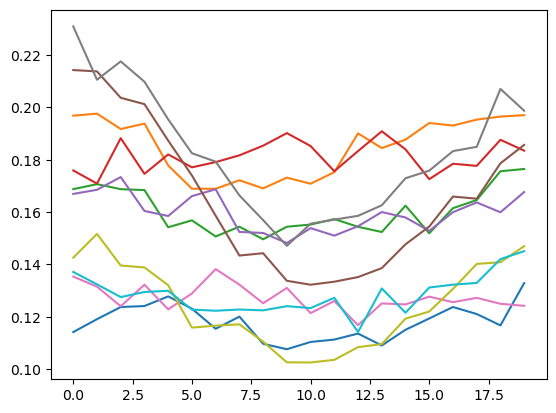

In [28]:
for i in range(stamp.shape[0]):
    plt.plot(stamp[i,:,10])

In [13]:
stampn = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_neg_better/images/ztf_20220820237546_000798_zr_c01_x_0001._1_stamps.npy")

In [12]:
infon = np.load("/lustre/lrspec/ZTF_data/training_feb26/stamps_neg_better/info/ztf_20220820237546_000798_zr_c01_x_0001._1_stamps_info.npy")

In [31]:
infon

array([[9.000e-01, 4.000e+00, 1.510e+02, 1.713e+03],
       [9.500e-01, 7.000e+00, 4.350e+02, 2.006e+03],
       [8.000e-01, 4.000e+00, 1.045e+03, 5.850e+02],
       [9.900e-01, 6.000e+00, 1.249e+03, 1.748e+03],
       [9.900e-01, 6.000e+00, 1.383e+03, 2.636e+03],
       [8.000e-01, 4.000e+00, 1.880e+03, 2.457e+03],
       [9.950e-01, 4.000e+00, 2.803e+03, 1.773e+03],
       [5.000e-01, 7.000e+00, 2.962e+03, 1.222e+03]])

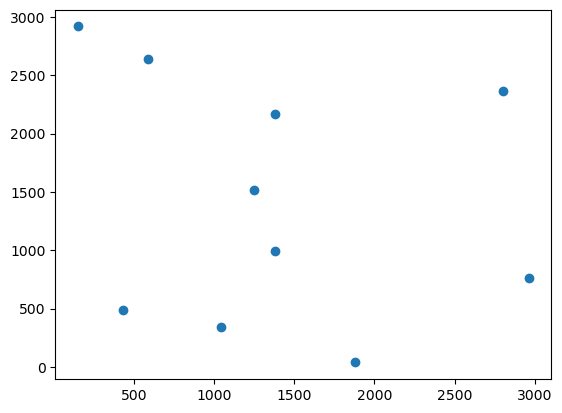

In [16]:
plt.scatter(info[:,2],info[:,3])

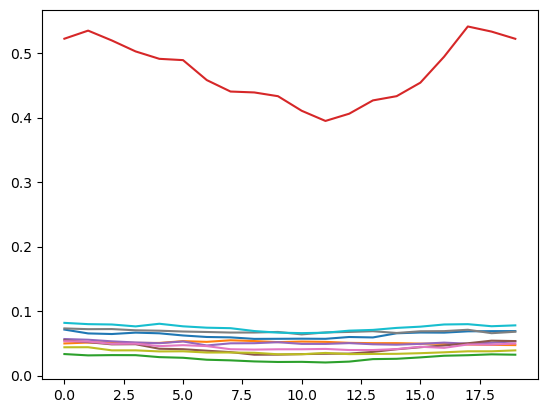

In [14]:
for i in range(stampn.shape[0]):
    plt.plot(stampn[i,:,10])

In [53]:
image_path = "/lustre/lrspec/ZTF_data/efficiency_testing/full_image_implantations_neg/images/"

In [58]:
image_file = np.load(image_path+"ztf_20220820237546_000798_zr_c01_x_0003._1_implanted_neg.npy")

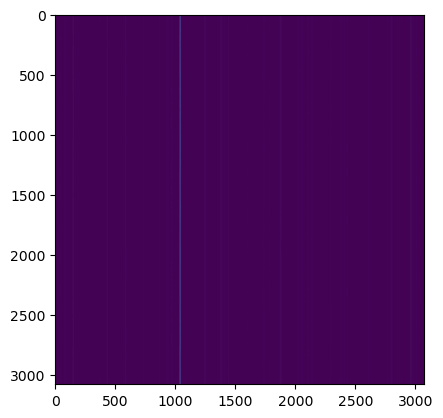

In [59]:
plt.imshow(image_file)

In [60]:
from scipy.signal import find_peaks

In [114]:
averages = np.average(image_file[20:-20,20:-20], axis=0) #cut off edges
peaks, heights = find_peaks(averages, height=(None, None))
min_height = np.sort(heights['peak_heights'])[-10]
tall_map = heights['peak_heights']>=min_height
tall_peaks = peaks[tall_map]+20

In [116]:
tall_peaks

array([ 150,  434, 1041, 1045, 1248, 1379, 1383, 1880, 2803, 2962])

In [112]:
tall_peaks

array([ 150,  434, 1041, 1045, 1248, 1379, 1383, 1880, 2803, 2962])

In [101]:
heights['peak_heights']

array([ 156.10496521,  152.81774902,  162.22715759,  157.16604614,
        160.86790466,  151.72853088,  169.50700378,  150.75906372,
        190.08740234,  150.7177887 ,  153.34341431,  168.18132019,
        150.76231384,  149.91938782,  152.75805664,  222.27708435,
        151.41355896,  153.92776489,  189.53599548,  159.19250488,
        151.35874939,  156.85961914,  159.70347595,  151.57533264,
        154.84339905,  152.22406006,  151.34294128,  533.434021  ,
        237.74833679,  159.23027039,  150.13916016,  203.89051819,
        161.18914795,  150.15623474,  149.01533508,  149.37306213,
        219.1696167 ,  152.08447266,  149.43548584,  166.50491333,
        150.08737183,  148.93434143,  148.74665833,  150.72676086,
        155.41616821,  160.89126587,  149.11039734,  156.34532166,
        152.20095825,  148.70683289,  152.23631287,  150.23553467,
        152.21499634,  150.36895752,  157.60482788,  148.43994141,
        148.31872559,  154.89015198,  160.03788757,  150.35609

In [76]:
[heights['peak_heights']>300].indices

AttributeError: 'list' object has no attribute 'indices'

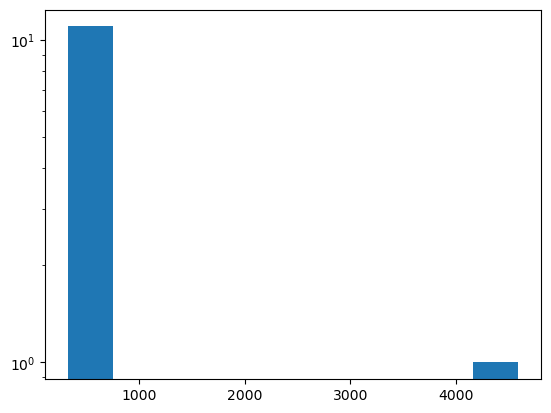

In [74]:
plt.hist(heights['peak_heights'][heights['peak_heights']>300])
plt.yscale("log")